# 05 – Random Forest

Many decision trees, each trained on a random sample of songs and looking at a random subset of features per split.
The prediction is the average vote of all trees.

Preprocessing: **none needed.** Trees only ask "is feature > threshold?", so scaling and log transforms change nothing,
and scikit-learn's Random Forest can handle NaN directly.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from utils import load_features, compare_to_baseline, save_predictions

# same plot style as in the other notebooks
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": GREY, "xtick.color": GREY, "ytick.color": GREY,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "figure.dpi": 110,
})

# data + features from features.py (target encodings learned on dev only)
dev, valid, test, X_dev, X_valid, X_test = load_features()
y_dev, y_valid = dev["music_hit"], valid["music_hit"]
print("X_dev:", X_dev.shape, "| X_valid:", X_valid.shape, "| X_test:", X_test.shape)

X_dev: (280040, 191) | X_valid: (70011, 191) | X_test: (87513, 191)


## Train

In [2]:
import time
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=300,       # number of trees
    min_samples_leaf=10,    # each leaf needs >= 10 songs -> smoother probabilities, less overfitting
    max_features="sqrt",    # each split looks at sqrt(191) ~ 14 random features
    n_jobs=-1,              # use all CPU cores
    random_state=42,
)

start = time.time()
model.fit(X_dev, y_dev)
print(f"training took {time.time() - start:.0f} s")

training took 16 s


## Validation AUC vs. baseline

In [3]:
valid_pred = model.predict_proba(X_valid)[:, 1]
auc = compare_to_baseline("Random Forest", y_valid, valid_pred)

Random Forest: validation AUC = 0.9662
baseline (artist_followers alone)  = 0.8747
improvement                        = +0.0915


## Feature importance
How much each feature reduced impurity across all splits of all trees.
(This measure favours features with many distinct values, so read it as a rough ranking.)

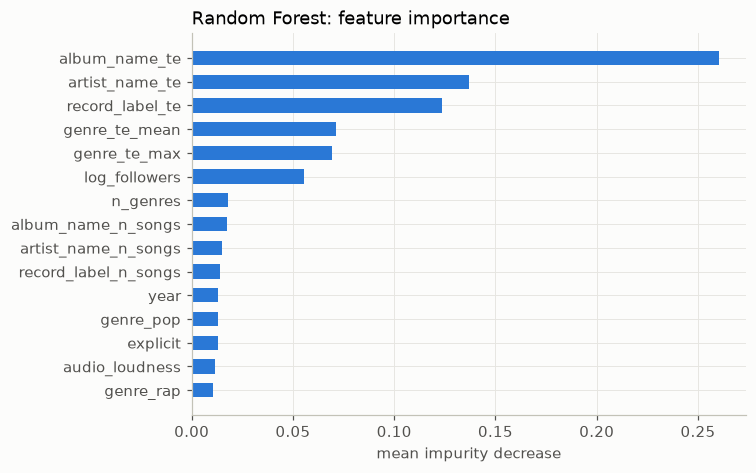

In [4]:
def plot_top_features(values, title, xlabel, n=15):
    """Horizontal bar chart of the n largest values (e.g. feature importances)."""
    top = values.sort_values(ascending=False).head(n)[::-1]  # biggest at the top
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.barh(top.index, top.values, color=BLUE, height=0.6)
    ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left")
    plt.show()

importance = pd.Series(model.feature_importances_, index=X_dev.columns)
plot_top_features(importance, "Random Forest: feature importance", "mean impurity decrease")

In [5]:
test_pred = model.predict_proba(X_test)[:, 1]
save_predictions("random_forest", valid, valid_pred, test, test_pred)